# Explorative Datenanalyse
LendingClub-Kredite 2007–2010. Die Befunde hier bestimmen Bereinigung, Features und Metriken der Pipeline.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

TARGET = "not.fully.paid"  # 1 = Kredit ausgefallen
df = pd.read_csv("../data/raw/loan_data.csv")
print(df.shape)
df.head(3)

(9578, 14)


,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0


In [2]:
print("Fehlende Werte:", df.isna().sum().sum())
print("Duplikate:", df.duplicated().sum())
print("revol.util > 100:", (df["revol.util"] > 100).sum())  # Erfassungsfehler → in clean() auf 100 begrenzen
df.describe().T.round(2)

Fehlende Werte: 0
Duplikate: 0
revol.util > 100: 27


,count,mean,std,min,25%,50%,75%,max
credit.policy,9578.0,0.80,0.40,0.00,1.00,1.00,1.00,1.00
int.rate,9578.0,0.12,0.03,0.06,0.10,0.12,0.14,0.22
installment,9578.0,319.09,207.07,15.67,163.77,268.95,432.76,940.14
log.annual.inc,9578.0,10.93,0.61,7.55,10.56,10.93,11.29,14.53
dti,9578.0,12.61,6.88,0.00,7.21,12.66,17.95,29.96
fico,9578.0,710.85,37.97,612.00,682.00,707.00,737.00,827.00
days.with.cr.line,9578.0,4560.77,2496.93,178.96,2820.00,4139.96,5730.00,17639.96
revol.bal,9578.0,16913.96,33756.19,0.00,3187.00,8596.00,18249.50,1207359.00
revol.util,9578.0,46.80,29.01,0.00,22.60,46.30,70.90,119.00
inq.last.6mths,9578.0,1.58,2.20,0.00,0.00,1.00,2.00,33.00


## Zielvariable und Verteilungen

Ausfallquote: 16.0%


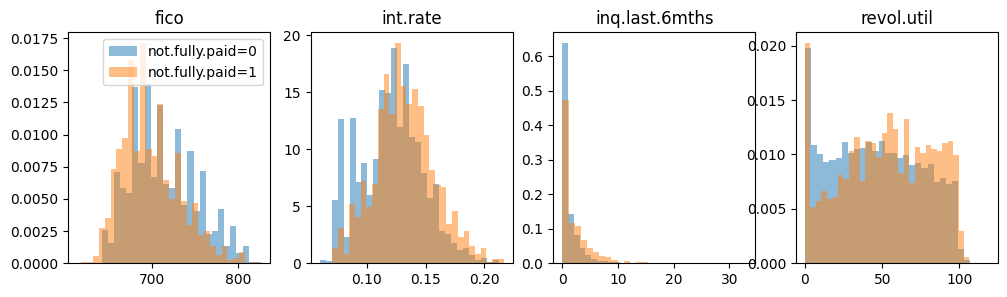

In [3]:
print(f"Ausfallquote: {df[TARGET].mean():.1%}")
# 16 % Ausfälle → Accuracy ist wertlos ("nie Ausfall" träfe 84 %).
# Daher: ROC-AUC/F1, class_weight="balanced", eigener Schwellenwert statt 0.5.

# Vier Spalten mit sichtbarem Unterschied zwischen den Klassen (nur zur Ansicht, keine Feature-Auswahl)
cols = ["fico", "int.rate", "inq.last.6mths", "revol.util"]
fig, axes = plt.subplots(1, len(cols), figsize=(12, 3))
for ax, col in zip(axes, cols, strict=True):
    for label, group in df.groupby(TARGET):
        ax.hist(group[col], bins=30, density=True, alpha=0.5, label=f"{TARGET}={label}")
    ax.set_title(col)
axes[0].legend()
plt.show()
# Ausfälle: niedrigerer FICO, höherer Zins, mehr Anfragen. Die Klassen überlappen stark → AUC um 0.68 realistisch.

## Risiko-Flags
Ausfallquote je Wertebereich. Schwellen → `src/config.py`, Flags → `add_risk_features()`.

In [4]:
def default_rate(col, bins):
    return df.groupby(pd.cut(df[col], bins), observed=True)[TARGET].agg(["mean", "size"]).round(3)


# FICO < 680: Quote steigt über 20 % → klare Schwelle (entspricht der üblichen Subprime-Grenze)
display(default_rate("fico", [600, 660, 680, 700, 740, 850]))
# Anfragen ≥ 3: Sprung von 14 % auf 21 % → klare Schwelle
display(df.groupby(df["inq.last.6mths"].clip(upper=6))[TARGET].mean().round(3))
# Zins > 13 %: stetiger Anstieg ohne Sprung, 13 % ≈ Median → Teil des Subprime-Flags
display(default_rate("int.rate", [0, 0.09, 0.11, 0.13, 0.15, 0.25]))
# revol.util > 60: kaum Sprung → weiche Konvention. Das Modell sieht zusätzlich den stetigen Wert.
display(default_rate("revol.util", [-1, 20, 40, 60, 80, 120]))
# dti > 25: erst ab 25 deutlicher Anstieg (18 % → 25 %)
display(default_rate("dti", [-1, 10, 15, 20, 25, 30]))

,mean,size
fico,,
"(600, 660]",0.309,489
"(660, 680]",0.215,1674
"(680, 700]",0.176,2058
"(700, 740]",0.153,3127
"(740, 850]",0.081,2230


inq.last.6mths
0    0.117
1    0.151
2    0.143
3    0.208
4    0.236
5    0.273
6    0.351
Name: not.fully.paid, dtype: float64

,mean,size
int.rate,,
"(0.0, 0.09]",0.054,1442
"(0.09, 0.11]",0.132,1419
"(0.11, 0.13]",0.158,2991
"(0.13, 0.15]",0.193,2312
"(0.15, 0.25]",0.248,1414


,mean,size
revol.util,,
"(-1, 20]",0.119,2173
"(20, 40]",0.141,1967
"(40, 60]",0.172,2054
"(60, 80]",0.168,1795
"(80, 120]",0.215,1589


,mean,size
dti,,
"(-1, 10]",0.148,3613
"(10, 15]",0.155,2271
"(15, 20]",0.168,2067
"(20, 25]",0.176,1475
"(25, 30]",0.250,152


In [5]:
# Signale summiert: Ausfallquote steigt monoton → risk_score als eigenes Feature
signals = pd.DataFrame(
    {
        "subprime": (df["fico"] < 680) | (df["int.rate"] > 0.13),
        "high_revol_util": df["revol.util"] > 60,
        "inquiries": df["inq.last.6mths"] >= 3,
        "delinquency": (df["delinq.2yrs"] > 0) | (df["pub.rec"] > 0),
        "high_dti": df["dti"] > 25,
    }
)
df.groupby(signals.sum(axis=1))[TARGET].agg(["mean", "size"]).round(3)

,mean,size
0,0.091,3201
1,0.158,2779
2,0.203,2444
3,0.262,996
4,0.300,150
5,0.375,8


## Verwendungszweck

In [6]:
# Kleingewerbe fällt fast dreimal so oft aus wie größere Anschaffungen → One-Hot-Encoding
df.groupby("purpose")[TARGET].agg(["mean", "size"]).sort_values("mean").round(3)

,mean,size
purpose,,
major_purchase,0.112,437
credit_card,0.116,1262
debt_consolidation,0.152,3957
all_other,0.166,2331
home_improvement,0.170,629
educational,0.201,343
small_business,0.278,619
